# Title: Monitoring Populist Language and Emotional Framing of Climate Change in German Political Discourse: An NLP Pipeline Using the AfD-CCC Corpus


4.1 Business problem
Imagine you are working as a Data Scientist for a climate communication organisation in Germany.

The organisation monitors public political communication to understand how climate change is discussed by political parties.

Manually reading thousands of speeches, press releases and Telegram messages is time-consuming.

The organisation needs an automated NLP system that can:
1. Identify populist language in political communication.
2. Identify negative and positive sentiment.
3. Detect specific emotions, particularly anger, fear and hope.
4. Discover recurring climate-related discussion themes.
5. Monitor how communication patterns change over time.
6. Produce evidence-based reports to support communication strategies.
Business value: The system helps analysts identify communication patterns, understand emotional framing and prioritise content for human review.

# 2 Supporting research questions:
- RQ1: How effectively can machine learning identify populist language in climate-related political texts?
- RQ2: Which emotions are most frequently expressed in the analysed texts?
- RQ3: How do sentiment and emotion patterns differ across communication sources?
- RQ4: What climate-related themes appear frequently in the corpus?
- RQ5: How do these patterns change over time?

# 3 High-level NLP architecture

Proposed NLP system architecture
1. Data collection

AfD-CCC CSV files: Bundestag, press releases, Telegram


2. Data understanding and preprocessing

Missing values · duplicates · German text cleaning · metadata · tokenisation


3. Feature engineering and dataset preparation

TF-IDF · labels · train/validation/test split


4A. Populist language

Gründl lexicon · supervised classifier · PopBERT comparison


4B. Sentiment

German-Sentiment-BERT · positive / negative / neutral


4C. Emotion detection

German emotion model · eight emotion categories


4D. Topic modelling

BERTopic or LDA · exploratory themes




5. Model evaluation and analysis

F1-score · precision · recall · confusion matrix · error analysis


6. Final reporting and recommendations

Emotion trends · populist language trends · source comparisons · visualisations

# 4 Detailed implementation of each component

Component 1: Data collection and understanding
Start with the three datasets you identified:
Dataset	Purpose
Bundestag	Formal parliamentary political communication
Press releases	Official party communication
Telegram	Social media-style political communication

# Import libraries

In [5]:
# Data handling
import pandas as pd
import numpy as np

# Text processing
import re
import unicodedata

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Date handling
from datetime import datetime

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


**Explanation**

We are importing the libraries required for data analysis.
- Pandas: reading and manipulating CSV files.
- NumPy: numerical operations.
- Matplotlib and Seaborn: charts and visualisations.
- Regex: text inspection and cleaning.
- Unicode: handling German characters.
We will not install transformer libraries yet. They are unnecessary for the initial dataset exploration.

# 2 – Define dataset URLs

In [7]:
dataset_urls = {
    "Bundestag": (
        "https://raw.githubusercontent.com/"
        "rmemminger/afd-ccc/main/data/"
        "bt_speeches_2017-2025.csv"
    ),

    "Press": (
        "https://raw.githubusercontent.com/"
        "rmemminger/afd-ccc/main/data/"
        "press_releases_2017-2021.csv"
    ),

    "Telegram": (
        "https://raw.githubusercontent.com/"
        "rmemminger/afd-ccc/main/data/"
        "telegram_2018-2025.csv"
    )
}

print("Dataset sources:")
for source, url in dataset_urls.items():
    print(source, ":", url)

Dataset sources:
Bundestag : https://raw.githubusercontent.com/rmemminger/afd-ccc/main/data/bt_speeches_2017-2025.csv
Press : https://raw.githubusercontent.com/rmemminger/afd-ccc/main/data/press_releases_2017-2021.csv
Telegram : https://raw.githubusercontent.com/rmemminger/afd-ccc/main/data/telegram_2018-2025.csv


# 3 – Load all three CSV files

In [8]:
raw_datasets = {}

for source, url in dataset_urls.items():

    df = pd.read_csv(
        url,
        encoding="utf-8",
        low_memory=False
    )

    raw_datasets[source] = df

    print("\nSource:", source)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

print("\nAll datasets loaded successfully.")


Source: Bundestag
Shape: (2284, 7)
Columns: ['Unnamed: 0', 'id', 'author', 'date', 'text', 'text_tokenised', 'token_count']

Source: Press
Shape: (911, 7)
Columns: ['Unnamed: 0', 'id', 'author', 'date', 'text', 'text_tokenised', 'token_count']

Source: Telegram
Shape: (766, 6)
Columns: ['Unnamed: 0', 'channel_id', 'date', 'text', 'text_tokenised', 'token_count']

All datasets loaded successfully.


**Explanation**

We use a dictionary called raw_datasets to store all three original datasets.

For each file, we display:
- Shape: number of rows and columns.
- Columns: available variables.
We are deliberately keeping the original data separate. This allows us to return to the original records if any preprocessing decision needs to be reviewed.

# 4 – Inspect the first records

In [9]:
for source, df in raw_datasets.items():

    print("\n" + "=" * 70)
    print("DATASET:", source)
    print("=" * 70)

    display(df.head(3))


DATASET: Bundestag


,Unnamed: 0,id,author,date,text,text_tokenised,token_count
0,0,sp19_4,Tino Chrupalla,2017-11-21,Aber auch die Grünen will ich nicht aus der Verantwortung entlassen. Schließlich hat die rot-grüne Regierung diese F...,Aber auch die Grünen will ich nicht aus der Verantwortung entlassen Schließlich hat die rotgrüne Regierung diese Fe...,131
1,1,sp19_4,Tino Chrupalla,2017-11-21,Mit gesunden Heimatmärkten hätten wir das Problem nicht; aber die Vorgabe des Zentralkomitees in Berlin war nun einm...,Mit gesunden Heimatmärkten hätten wir das Problem nicht aber die Vorgabe des Zentralkomitees in Berlin war nun einm...,59
2,2,sp19_9,Heiko Heßenkemper,2017-11-21,Zurück zu Siemens. Hier ist jetzt die Kraftwerkssparte betroffen. Aber wer ist denn verantwortlich für die unstruktu...,Zurück zu Siemens Hier ist jetzt die Kraftwerkssparte betroffen Aber wer ist denn verantwortlich für die unstruktu...,49



DATASET: Press


,Unnamed: 0,id,author,date,text,text_tokenised,token_count
0,0,press_0,Leif-Erik Holm,2017-10-27,"Jamaika-Koalitionäre torpedieren deutsche Energiesicherheit Berlin, 27. Oktober 2017. Zur Ankündigung führender Poli...",JamaikaKoalitionäre torpedieren deutsche Energiesicherheit Berlin 27 Oktober 2017 Zur Ankündigung führender Politik...,111
1,1,press_0,Leif-Erik Holm,2017-10-27,Mit Zappelstrom aus Wind- und Solarenergie können wir keine stabile Stromversorgung sicherstellen. Es sollte auch au...,Mit Zappelstrom aus Wind und Solarenergie können wir keine stabile Stromversorgung sicherstellen Es sollte auch aus...,106
2,2,press_0,Leif-Erik Holm,2017-10-27,"Ich bin wirklich gespannt, ob die Bundeskanzlerin mal wieder eine Rolle rückwärts hinlegt und das ‚Nord-Stream-2‘-Pr...",Ich bin wirklich gespannt ob die Bundeskanzlerin mal wieder eine Rolle rückwärts hinlegt und das ‚ NordStream2‘Proj...,43



DATASET: Telegram


,Unnamed: 0,channel_id,date,text,text_tokenised,token_count
0,0,1326276537,2025-01-16,"Dr. Dominik Kaufner gestern mit den 400 (!) Demonstranten vor dem Landtag. Dass der RBB keinen Journalismus kann, is...",Dr Dominik Kaufner gestern mit den 400 Demonstranten vor dem Landtag Dass der RBB keinen Journalismus kann ist ...,43
1,1,1326276537,2025-01-15,Im Video sehen Sie die Groteske um die Besetzung des Vorsitzes des Bildungsausschusses im Landtag Brandenburg. Dr. D...,Im Video sehen Sie die Groteske um die Besetzung des Vorsitzes des Bildungsausschusses im Landtag Brandenburg Dr Do...,57
2,2,1326276537,2025-01-14,"Es fühlt sich an wie 1989! Die Verbote werden immer verrückter, die Gängelungen schlimmer – aber zugleich finden imm...",Es fühlt sich an wie 1989 Die Verbote werden immer verrückter die Gängelungen schlimmer – aber zugleich finden imm...,76


**What should you look for?**

Examine the following:
- Is the German text readable?
- Are dates present?
- Are authors available?
- Does the text contain multiple sentences?
- Is the tokenised text different from the original text?

# 5 – Check dataset dimensions and missing values

In [10]:
for source, df in raw_datasets.items():

    print("\nDATASET:", source)

    print("Total records:", len(df))

    print("\nMissing values:")
    display(df.isnull().sum().to_frame("Missing Count"))

    print("\nData types:")
    display(df.dtypes.to_frame("Data Type"))


DATASET: Bundestag
Total records: 2284

Missing values:


,Missing Count
Unnamed: 0,0
id,0
author,0
date,0
text,0
text_tokenised,0
token_count,0



Data types:


,Data Type
Unnamed: 0,int64
id,object
author,object
date,object
text,object
text_tokenised,object
token_count,int64



DATASET: Press
Total records: 911

Missing values:


,Missing Count
Unnamed: 0,0
id,0
author,58
date,0
text,0
text_tokenised,0
token_count,0


... (2 outputs left out)


DATASET: Telegram
Total records: 766

Missing values:


,Missing Count
Unnamed: 0,0
channel_id,0
date,0
text,0
text_tokenised,0
token_count,0



Data types:


,Data Type
Unnamed: 0,int64
channel_id,int64
date,object
text,object
text_tokenised,object
token_count,int64


# 6 – Create a dataset summary

In [11]:
summary = []

for source, df in raw_datasets.items():

    summary.append({
        "Source": source,
        "Total Records": len(df),
        "Missing Text": df["text"].isna().sum(),
        "Duplicate Text": df["text"].duplicated().sum(),
        "Unique Dates": df["date"].nunique(),
        "Available Columns": len(df.columns)
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Source,Total Records,Missing Text,Duplicate Text,Unique Dates,Available Columns
0,Bundestag,2284,0,92,372,7
1,Press,911,0,4,372,7
2,Telegram,766,0,63,536,6


**Explanation**

This gives us a comparison of the three data sources.

We also check repeated text within each individual dataset.

A repeated statement does not always mean the record is invalid. It could have been published more than once or appear in different contexts.

For that reason, we will identify duplicates first and decide how to handle them later.

# 7 – Check publication dates

In [12]:
for source, df in raw_datasets.items():

    dates = pd.to_datetime(
        df["date"],
        errors="coerce"
    )

    print("\nSource:", source)
    print("Earliest date:", dates.min())
    print("Latest date:", dates.max())
    print("Invalid dates:", dates.isna().sum())


Source: Bundestag
Earliest date: 2017-11-21 00:00:00
Latest date: 2025-03-18 00:00:00
Invalid dates: 115

Source: Press
Earliest date: 2017-10-27 00:00:00
Latest date: 2021-10-22 00:00:00
Invalid dates: 0

Source: Telegram
Earliest date: 2018-10-27 00:00:00
Latest date: 2025-01-22 00:00:00
Invalid dates: 0


**Explanation**

Date analysis will be important in the later phases.

For example, we may investigate whether emotional framing changes over time.

We should also remember that the three sources cover different time periods. A comparison between sources must take this into account.

# 8 – Analyse text length

In [13]:
for source, df in raw_datasets.items():

    text_length = df["text"].dropna().astype(str).str.len()

    print("\nSource:", source)

    print("Average characters:", round(text_length.mean(), 2))
    print("Minimum characters:", text_length.min())
    print("Maximum characters:", text_length.max())
    print("Median characters:", text_length.median())


Source: Bundestag
Average characters: 677.85
Minimum characters: 61
Maximum characters: 1000
Median characters: 804.5

Source: Press
Average characters: 705.36
Minimum characters: 65
Maximum characters: 1000
Median characters: 833.0

Source: Telegram
Average characters: 405.71
Minimum characters: 59
Maximum characters: 997
Median characters: 343.0


**Explanation**

Different communication channels have different writing styles.

For example:
- Parliamentary speeches can contain longer arguments.
- Press releases can contain multiple paragraphs.
- Telegram messages can be shorter and more informal.
This information will help us decide whether to analyse entire documents or split them into sentences.

For the current project, we will initially use the available text records as our units of analysis.

# 9 – Visualise the number of records by source

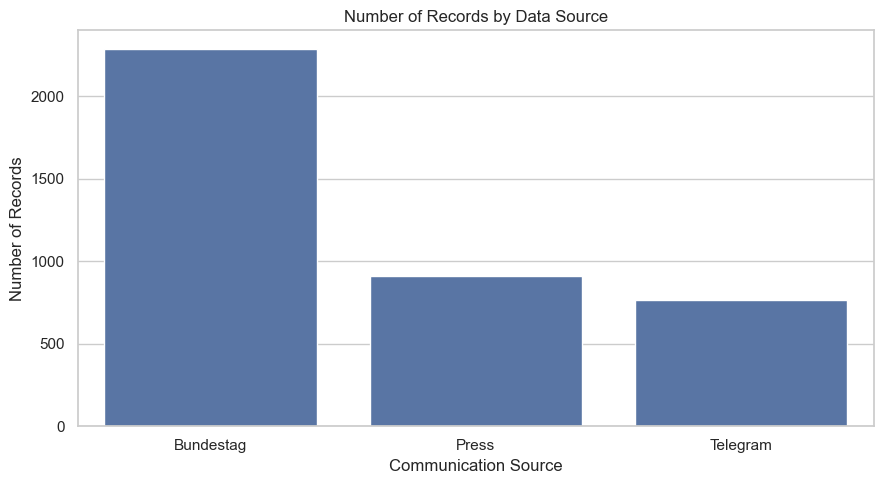

In [14]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=summary_df,
    x="Source",
    y="Total Records"
)

plt.title("Number of Records by Data Source")
plt.xlabel("Communication Source")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

**Explanation**

This chart helps us understand which communication source contributes the most records.

It is important because an unequal distribution can affect our overall analysis.

For example, if one source contains substantially more records, its results may dominate the combined dataset.

# 10 – Analyse text-length distribution

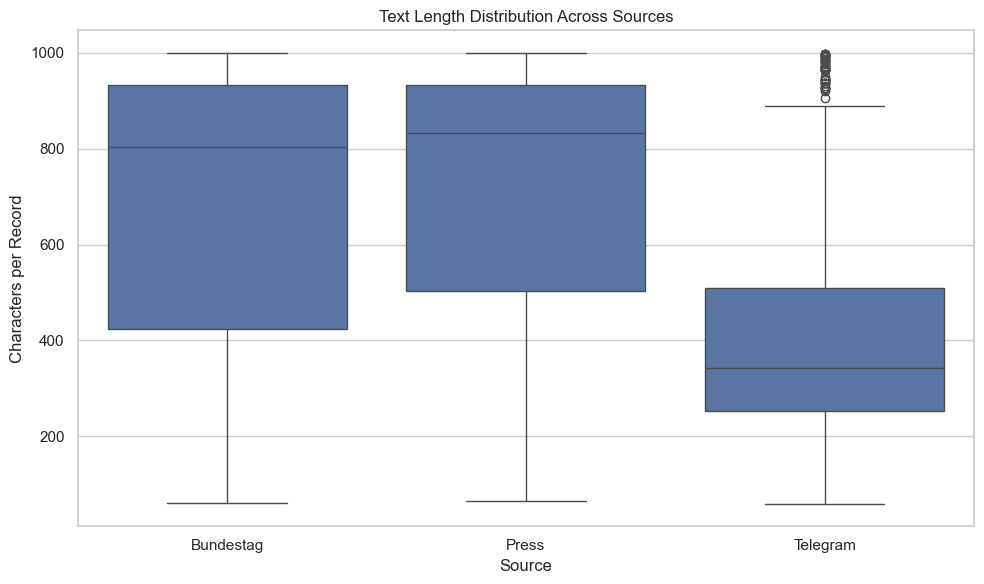

In [15]:
length_data = []

for source, df in raw_datasets.items():

    temp = df[["text"]].dropna().copy()

    temp["Text Length"] = (
        temp["text"].astype(str).str.len()
    )

    temp["Source"] = source

    length_data.append(temp)

length_df = pd.concat(
    length_data,
    ignore_index=True
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=length_df,
    x="Source",
    y="Text Length"
)

plt.title("Text Length Distribution Across Sources")
plt.xlabel("Source")
plt.ylabel("Characters per Record")

plt.tight_layout()
plt.show()

**Explanation**

A boxplot helps us identify:
- Median text length.
- Variation in text length.
- Unusually long records.
- Differences between communication sources.

# 11 – Investigate climate-related relevance
As mentioned earlier, some initial Telegram records do not appear to discuss climate change.

In [16]:
climate_keywords = [
    "klima",
    "klimawandel",
    "klimakrise",
    "klimaschutz",
    "klimapolitik",
    "klimaneutral",
    "co2",
    "co₂",
    "treibhaus",
    "emission",
    "energiewende",
    "erneuerbare",
    "windkraft",
    "solarenergie",
    "kohlekraft",
    "kohleausstieg"
]

pattern = re.compile(
    r"\b(?:" + "|".join(
        re.escape(word) for word in climate_keywords
    ) + r")\w*",
    flags=re.IGNORECASE
)

for source, df in raw_datasets.items():

    texts = df["text"].fillna("").astype(str)

    matches = texts.str.contains(pattern)

    print("\nSource:", source)
    print("Total records:", len(df))
    print("Keyword matches:", matches.sum())
    print(
        "Keyword match percentage:",
        round(matches.mean() * 100, 2),
        "%"
    )


Source: Bundestag
Total records: 2284
Keyword matches: 1676
Keyword match percentage: 73.38 %

Source: Press
Total records: 911
Keyword matches: 719
Keyword match percentage: 78.92 %

Source: Telegram
Total records: 766
Keyword matches: 167
Keyword match percentage: 21.8 %


**Explanation**

We are checking how many records contain at least one climate-related keyword.

This is only a data-quality diagnostic.

It is not a complete climate-topic classifier because:
- Some climate-related statements may not contain these words.
- Some keyword matches may refer to other topics.
- Words such as Energiewende may occur in broader energy-policy discussions.
Do not automatically delete all records without keyword matches.

Instead, investigate the unmatched Telegram messages and compare a sample with the research corpus methodology.

# 12 – Inspect examples of potentially irrelevant Telegram records

In [17]:
telegram_df = raw_datasets["Telegram"].copy()

telegram_texts = telegram_df["text"].fillna("").astype(str)

telegram_df["climate_keyword_match"] = (
    telegram_texts.str.contains(pattern)
)

display(
    telegram_df.loc[
        ~telegram_df["climate_keyword_match"],
        ["date", "text"]
    ].head(15)
)

,date,text
0,2025-01-16,"Dr. Dominik Kaufner gestern mit den 400 (!) Demonstranten vor dem Landtag. Dass der RBB keinen Journalismus kann, is..."
1,2025-01-15,Im Video sehen Sie die Groteske um die Besetzung des Vorsitzes des Bildungsausschusses im Landtag Brandenburg. Dr. D...
3,2025-01-09,"Wenn ""echte"" Demokraten zur Störaktion ansetzen Beim Bürgerdialog der AfD-Fraktion haben sich gestern auch ein paar ..."
4,2025-01-08,Musk und die Meinungsfreiheit sind dem Öffentlichen-Rechtlichen- Rundfunk ein Dorn im Augen. @Dennis Hohloch
5,2025-01-06,"Filmvorführung: ""Nur ein Piks - im Schatten der Impfung"" Potsdam, Landtag Brandenburg, Alter Markt 1, 14467 Potsdam ..."
6,2024-12-13,"Syrer müssen zurück in ihr Heimatland! Der Fluchtgrund, weshalb viele Syrer in Deutschland Asyl bekommen haben, ist ..."
7,2024-12-12,Diäten: Sie gönnen sich den nächsten Batzen! Zwei Dinge haben wir geschafft mit unserem Gesetzesentwurf gegen die au...
8,2024-12-11,Wackeliges Wahlergebnis für Woidke In Brandenburg geht es schleppend weiter wie bisher – mit Dietmar Woidke in der S...
11,2024-11-11,"Ampel stoppen, Wirtschaft retten! ZF in Brandenburg, Fuldaer in Fürstenwalde, Mercedes Benz in Ludwigsfelde: Branden..."
12,2024-11-05,"Und wer immer mehr illegale Migranten rundum versorgen will, der hat auch irgendwann kein Geld mehr.“"


**This gives us actual examples to inspect.**

We want to establish whether the Telegram file contains:
1. Climate-related messages.
2. General political messages.
3. Unrelated messages.
This is an important step because our research question concerns climate change communication, not general AfD communication.

If the file includes unrelated content, we will need to investigate the repository's collection and filtering process before deciding on a defensible inclusion rule.

# 13 – Create a standardised combined dataset
Now we will bring all three sources together.

We will retain the original text and metadata.

In [18]:
standard_datasets = []

for source, df in raw_datasets.items():

    temp = df.copy()

    # Preserve original CSV index if present
    if "Unnamed: 0" in temp.columns:
        temp = temp.rename(
            columns={"Unnamed: 0": "original_row"}
        )

    # Add missing metadata columns
    for col in [
        "id",
        "author",
        "channel_id",
        "date",
        "text",
        "text_tokenised",
        "token_count"
    ]:
        if col not in temp.columns:
            temp[col] = np.nan

    temp["source"] = source

    # Create a source-specific record identifier
    temp["record_id"] = (
        source + "_" + temp.index.astype(str)
    )

    # Standard date format
    temp["date"] = pd.to_datetime(
        temp["date"],
        errors="coerce"
    )

    standard_datasets.append(temp)

combined_df = pd.concat(
    standard_datasets,
    ignore_index=True,
    sort=False
)

print("Combined dataset shape:", combined_df.shape)

display(combined_df.head())

Combined dataset shape: (3961, 10)


,original_row,id,author,date,text,text_tokenised,token_count,channel_id,source,record_id
0,0,sp19_4,Tino Chrupalla,2017-11-21,Aber auch die Grünen will ich nicht aus der Verantwortung entlassen. Schließlich hat die rot-grüne Regierung diese F...,Aber auch die Grünen will ich nicht aus der Verantwortung entlassen Schließlich hat die rotgrüne Regierung diese Fe...,131,NaN,Bundestag,Bundestag_0
1,1,sp19_4,Tino Chrupalla,2017-11-21,Mit gesunden Heimatmärkten hätten wir das Problem nicht; aber die Vorgabe des Zentralkomitees in Berlin war nun einm...,Mit gesunden Heimatmärkten hätten wir das Problem nicht aber die Vorgabe des Zentralkomitees in Berlin war nun einm...,59,NaN,Bundestag,Bundestag_1
2,2,sp19_9,Heiko Heßenkemper,2017-11-21,Zurück zu Siemens. Hier ist jetzt die Kraftwerkssparte betroffen. Aber wer ist denn verantwortlich für die unstruktu...,Zurück zu Siemens Hier ist jetzt die Kraftwerkssparte betroffen Aber wer ist denn verantwortlich für die unstruktu...,49,NaN,Bundestag,Bundestag_2
3,3,sp19_14,Marc Bernhard,2017-11-21,Stattdessen führt jedoch eine von Ihnen grünäugig entworfene und von einem SPD-geführten Ministerium dilettantisch u...,Stattdessen führt jedoch eine von Ihnen grünäugig entworfene und von einem SPDgeführten Ministerium dilettantisch um...,40,NaN,Bundestag,Bundestag_3
4,4,sp19_21,Karsten Hilse,2017-11-21,Frau Präsidentin! Werte Kollegen! Offensichtlich haben die Grünen das Thema „schneller Kohleausstieg“ in den letzten...,Frau Präsidentin Werte Kollegen Offensichtlich haben die Grünen das Thema „ schneller Kohleausstieg “ in den letzt...,127,NaN,Bundestag,Bundestag_4


**Explanation**

We now have one combined dataset.

The source column allows us to distinguish between Bundestag, Press and Telegram.

We have also preserved author and channel information where available.

Notice that we have not removed duplicates or filtered out any text yet.

# 14 – Create a quality-controlled working dataset
We can now remove records that have no usable text.

We will also standardise whitespace in a separate column without changing the original text.

In [19]:
analysis_df = combined_df.copy()

# Remove missing or empty text
analysis_df = analysis_df[
    analysis_df["text"].notna()
].copy()

analysis_df["text"] = (
    analysis_df["text"].astype(str).str.strip()
)

analysis_df = analysis_df[
    analysis_df["text"] != ""
].copy()

# Create a minimally normalised text column
analysis_df["text_clean"] = (
    analysis_df["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Count words using whitespace separation
analysis_df["word_count"] = (
    analysis_df["text_clean"].str.split().str.len()
)

# Climate keyword diagnostic
analysis_df["climate_keyword_match"] = (
    analysis_df["text_clean"].str.contains(pattern)
)

print("Original combined records:", len(combined_df))
print("Usable text records:", len(analysis_df))
print(
    "Removed records:",
    len(combined_df) - len(analysis_df)
)

display(analysis_df.head())

Original combined records: 3961
Usable text records: 3961
Removed records: 0


,original_row,id,author,date,text,text_tokenised,token_count,channel_id,source,record_id,text_clean,word_count,climate_keyword_match
0,0,sp19_4,Tino Chrupalla,2017-11-21,Aber auch die Grünen will ich nicht aus der Verantwortung entlassen. Schließlich hat die rot-grüne Regierung diese F...,Aber auch die Grünen will ich nicht aus der Verantwortung entlassen Schließlich hat die rotgrüne Regierung diese Fe...,131,NaN,Bundestag,Bundestag_0,Aber auch die Grünen will ich nicht aus der Verantwortung entlassen. Schließlich hat die rot-grüne Regierung diese F...,129,True
1,1,sp19_4,Tino Chrupalla,2017-11-21,Mit gesunden Heimatmärkten hätten wir das Problem nicht; aber die Vorgabe des Zentralkomitees in Berlin war nun einm...,Mit gesunden Heimatmärkten hätten wir das Problem nicht aber die Vorgabe des Zentralkomitees in Berlin war nun einm...,59,NaN,Bundestag,Bundestag_1,Mit gesunden Heimatmärkten hätten wir das Problem nicht; aber die Vorgabe des Zentralkomitees in Berlin war nun einm...,57,True
2,2,sp19_9,Heiko Heßenkemper,2017-11-21,Zurück zu Siemens. Hier ist jetzt die Kraftwerkssparte betroffen. Aber wer ist denn verantwortlich für die unstruktu...,Zurück zu Siemens Hier ist jetzt die Kraftwerkssparte betroffen Aber wer ist denn verantwortlich für die unstruktu...,49,NaN,Bundestag,Bundestag_2,Zurück zu Siemens. Hier ist jetzt die Kraftwerkssparte betroffen. Aber wer ist denn verantwortlich für die unstruktu...,49,True
3,3,sp19_14,Marc Bernhard,2017-11-21,Stattdessen führt jedoch eine von Ihnen grünäugig entworfene und von einem SPD-geführten Ministerium dilettantisch u...,Stattdessen führt jedoch eine von Ihnen grünäugig entworfene und von einem SPDgeführten Ministerium dilettantisch um...,40,NaN,Bundestag,Bundestag_3,Stattdessen führt jedoch eine von Ihnen grünäugig entworfene und von einem SPD-geführten Ministerium dilettantisch u...,40,True
4,4,sp19_21,Karsten Hilse,2017-11-21,Frau Präsidentin! Werte Kollegen! Offensichtlich haben die Grünen das Thema „schneller Kohleausstieg“ in den letzten...,Frau Präsidentin Werte Kollegen Offensichtlich haben die Grünen das Thema „ schneller Kohleausstieg “ in den letzt...,127,NaN,Bundestag,Bundestag_4,Frau Präsidentin! Werte Kollegen! Offensichtlich haben die Grünen das Thema „schneller Kohleausstieg“ in den letzten...,125,True


**Explanation**

We are only removing records without usable text.

We are not removing punctuation, German stop words or negations.

The new text_clean column will be useful for later processing, while text remains our original source text.

# 15 – Final source-wise quality report

In [20]:
quality_report = (
    analysis_df.groupby("source")
    .agg(
        total_records=("record_id", "count"),
        unique_texts=("text_clean", "nunique"),
        missing_dates=("date", lambda x: x.isna().sum()),
        average_words=("word_count", "mean"),
        median_words=("word_count", "median"),
        climate_keyword_matches=(
            "climate_keyword_match", "sum"
        )
    )
    .reset_index()
)

quality_report["average_words"] = (
    quality_report["average_words"].round(2)
)

display(quality_report)

,source,total_records,unique_texts,missing_dates,average_words,median_words,climate_keyword_matches
0,Bundestag,2284,2192,115,96.17,111.0,1676
1,Press,911,907,0,91.81,106.0,719
2,Telegram,766,703,0,54.00,45.0,167


# 16 – Save  Phase 1 dataset

In [24]:
import os

PROJECT_DIR = "/content/M508_AfD_CCC_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project folder created:", PROJECT_DIR)
print("Folder exists:", os.path.exists(PROJECT_DIR))

Project folder created: /content/M508_AfD_CCC_Project
Folder exists: True


In [25]:
folders = [
    "data/raw",
    "data/processed",
    "outputs/eda",
    "outputs/models",
    "outputs/visualisations",
    "reports"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

print("All project folders created successfully.")

All project folders created successfully.


In [26]:
# Save original combined dataset
combined_df.to_csv(
    f"{PROJECT_DIR}/data/raw/afd_ccc_combined_raw.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save cleaned dataset
analysis_df.to_csv(
    f"{PROJECT_DIR}/data/processed/afd_ccc_phase1_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save quality report
quality_report.to_csv(
    f"{PROJECT_DIR}/outputs/eda/afd_ccc_quality_report.csv",
    index=False,
    encoding="utf-8-sig"
)

print("All Phase 1 files saved successfully!")

All Phase 1 files saved successfully!


In [27]:
#  Verify saved files
for root, dirs, files in os.walk(PROJECT_DIR):
    for file in files:
        print(os.path.join(root, file))

/content/M508_AfD_CCC_Project\data\processed\afd_ccc_phase1_clean.csv
/content/M508_AfD_CCC_Project\data\raw\afd_ccc_combined_raw.csv
/content/M508_AfD_CCC_Project\outputs\eda\afd_ccc_quality_report.csv
